In [1]:
import pandas as pd
import json
import scipy
from sklearn.preprocessing import StandardScaler

import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import numpy as np


In [2]:
df = pd.read_csv('cgmacros_final.csv')
df['Libre_trace'] = df['Libre_trace'].apply(json.loads) 

In [3]:
print(df.columns)

Index(['subject', 'Meal_Type', 'Timestamp', 'Libre_trace', 'Baseline_Libre',
       'iAUC_libre', 'AUC_libre', 'Calories', 'Carbs_g', 'Protein_g', 'Fat_g',
       'Fiber_g', 'Activity_pre_sum', 'Activity_post_sum', 'Health_group',
       'Age', 'Gender', 'BMI', 'A1c', 'Fasting_glucose', 'Insulin', 'HOMA_IR',
       'Triglycerides', 'Cholesterol', 'HDL', 'Non_HDL', 'LDL', 'VLDL',
       'Cho_HDL_ratio'],
      dtype='str')


In [5]:
# Encode gender the same way as the paper: M=1, F=-1
df['Gender_encoded'] = df['Gender'].apply(
    lambda x: 1 if str(x).strip().upper() in ['M', 'MALE'] else -1
)

# Encode the meal type once on the full dataframe
df['Meal_Type_encoded'] = df['Meal_Type'].map(
    {'Breakfast': 0, 'Lunch': 1, 'Dinner': 2}
)


# Convert macros grams -> kcal (match paper exactly)
df['Carbs_kcal']   = df['Carbs_g']   * 4
df['Protein_kcal'] = df['Protein_g'] * 4
df['Fat_kcal']     = df['Fat_g']      * 9
df['Fiber_kcal']   = df['Fiber_g']    * 2
df['Net_Carb']     = df['Carbs_g']    - df['Fiber_g']

In [6]:
FEATURES = [
    # Macros (kcal, matching paper)
    'Carbs_kcal', 'Protein_kcal', 'Fat_kcal', 'Fiber_kcal',
    # Clinical - all of them
    'Baseline_Libre', 'Age', 'Gender_encoded', 'BMI', 'A1c', 'HOMA_IR',
    'Insulin', 'Triglycerides', 'Cholesterol', 'HDL', 'Non_HDL',
    'LDL', 'VLDL', 'Cho_HDL_ratio', 'Fasting_glucose',
    # Your additions  (not in the paper):
    'Calories', 'Activity_pre_sum', 'Activity_post_sum',
]

# General model features — everything + meal type
FEATURES_GENERAL = FEATURES + ['Meal_Type_encoded']

TARGET = 'iAUC_libre'

In [7]:
breakfast_df = df[df['Meal_Type'] == 'Breakfast'].copy()
lunch_df     = df[df['Meal_Type'] == 'Lunch'].copy()
dinner_df    = df[df['Meal_Type'] == 'Dinner'].copy()

print(f"Breakfast: {len(breakfast_df)} meals, {breakfast_df['subject'].nunique()} subjects")
print(f"Lunch:     {len(lunch_df)} meals, {lunch_df['subject'].nunique()} subjects")
print(f"Dinner:    {len(dinner_df)} meals, {dinner_df['subject'].nunique()} subjects")

Breakfast: 405 meals, 44 subjects
Lunch:     369 meals, 44 subjects
Dinner:    396 meals, 43 subjects


In [8]:
def train_xgboost_loso(df, features, label='Model', target='iAUC_libre', use_paper_params=True):
    
    subjects    = df['subject'].unique()
    pred_list, true_list, subj_list, hgroup_list = [], [], [], []

    if use_paper_params:
        params = dict(max_depth=1, n_estimators=80, learning_rate=0.2,
                      reg_alpha=1, reg_lambda=0)
    else:
        params = dict(max_depth=4, n_estimators=500, learning_rate=0.05,
                      subsample=0.8, colsample_bytree=0.8,
                      reg_alpha=0.1, reg_lambda=1.0)

    for sub in subjects:
        train_df = df[df['subject'] != sub]
        test_df  = df[df['subject'] == sub]

        X_train = train_df[features].values
        y_train = train_df[target].values          
        X_test  = test_df[features].values
        y_test  = test_df[target].values           

        scaler  = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test  = scaler.transform(X_test)

        mdl = xgb.XGBRegressor(**params, random_state=42)
        mdl.fit(X_train, y_train)

        preds = mdl.predict(X_test)
        pred_list.extend(preds)
        true_list.extend(y_test)
        subj_list.extend([sub] * len(y_test))
        hgroup_list.extend(test_df['Health_group'].values)

    pred_array = np.array(pred_list)
    true_array = np.array(true_list)

    r, p  = scipy.stats.pearsonr(pred_array, true_array)
    rmse  = np.sqrt(mean_squared_error(true_array, pred_array))
    mae   = mean_absolute_error(true_array, pred_array)
    r2    = r2_score(true_array, pred_array)

    print(f"\n  {label}  [{target}] (LOSO, n={len(df)} meals, {len(subjects)} subjects)")
    print(f"{'='*55}")
    print(f"  Pearson r : {r:.4f}  (p={p:.2e})")
    print(f"  RMSE      : {rmse:.1f}")
    print(f"  MAE       : {mae:.1f}")
    print(f"  R²        : {r2:.3f}")

    results_df = pd.DataFrame({
        'subject': subj_list, 'Health_group': hgroup_list,
        'y_true': true_array, 'y_pred': pred_array
    })
    return results_df, {'label': label, 'target': target, 'r': r, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

In [9]:
# iAUC experiments
res_2a, met_2a = train_xgboost_loso(breakfast_df, FEATURES, label='2a — Breakfast', target='iAUC_libre')
res_2b, met_2b = train_xgboost_loso(lunch_df,     FEATURES, label='2b — Lunch',     target='iAUC_libre')
res_2c, met_2c = train_xgboost_loso(dinner_df,    FEATURES, label='2c — Dinner',    target='iAUC_libre')
res_2d, met_2d = train_xgboost_loso(df, FEATURES_GENERAL, label='2d — General', target='iAUC_libre')

# AUC experiments — identical calls, just change target
res_2a_auc, met_2a_auc = train_xgboost_loso(breakfast_df, FEATURES, label='2a — Breakfast', target='AUC_libre')
res_2b_auc, met_2b_auc = train_xgboost_loso(lunch_df,     FEATURES, label='2b — Lunch',     target='AUC_libre')
res_2c_auc, met_2c_auc = train_xgboost_loso(dinner_df,    FEATURES, label='2c — Dinner',    target='AUC_libre')
res_2d_auc, met_2d_auc = train_xgboost_loso(df, FEATURES_GENERAL, label='2d — General', target='AUC_libre')


  2a — Breakfast  [iAUC_libre] (LOSO, n=405 meals, 44 subjects)
  Pearson r : 0.6555  (p=4.37e-51)
  RMSE      : 2596.8
  MAE       : 1877.2
  R²        : 0.429

  2b — Lunch  [iAUC_libre] (LOSO, n=369 meals, 44 subjects)
  Pearson r : 0.4880  (p=1.80e-23)
  RMSE      : 2355.3
  MAE       : 1808.1
  R²        : 0.220

  2c — Dinner  [iAUC_libre] (LOSO, n=396 meals, 43 subjects)
  Pearson r : 0.2568  (p=2.20e-07)
  RMSE      : 2170.5
  MAE       : 1566.5
  R²        : 0.018

  2d — General  [iAUC_libre] (LOSO, n=1170 meals, 44 subjects)
  Pearson r : 0.4694  (p=3.68e-65)
  RMSE      : 2550.1
  MAE       : 1877.6
  R²        : 0.217

  2a — Breakfast  [AUC_libre] (LOSO, n=405 meals, 44 subjects)
  Pearson r : 0.8772  (p=1.83e-130)
  RMSE      : 2943.4
  MAE       : 2158.3
  R²        : 0.763

  2b — Lunch  [AUC_libre] (LOSO, n=369 meals, 44 subjects)
  Pearson r : 0.7942  (p=2.13e-81)
  RMSE      : 2564.1
  MAE       : 1944.6
  R²        : 0.627

  2c — Dinner  [AUC_libre] (LOSO, n=396 

    Model  N_meals  iAUC_r  iAUC_R2  iAUC_RMSE  AUC_r  AUC_R2  AUC_RMSE
Breakfast      405   0.655    0.429   2596.793  0.877   0.763  2943.358
    Lunch      369   0.488    0.220   2355.344  0.794   0.627  2564.087
   Dinner      396   0.257    0.018   2170.520  0.729   0.526  2556.760
  General     1170   0.469    0.217   2550.116  0.829   0.682  2822.399


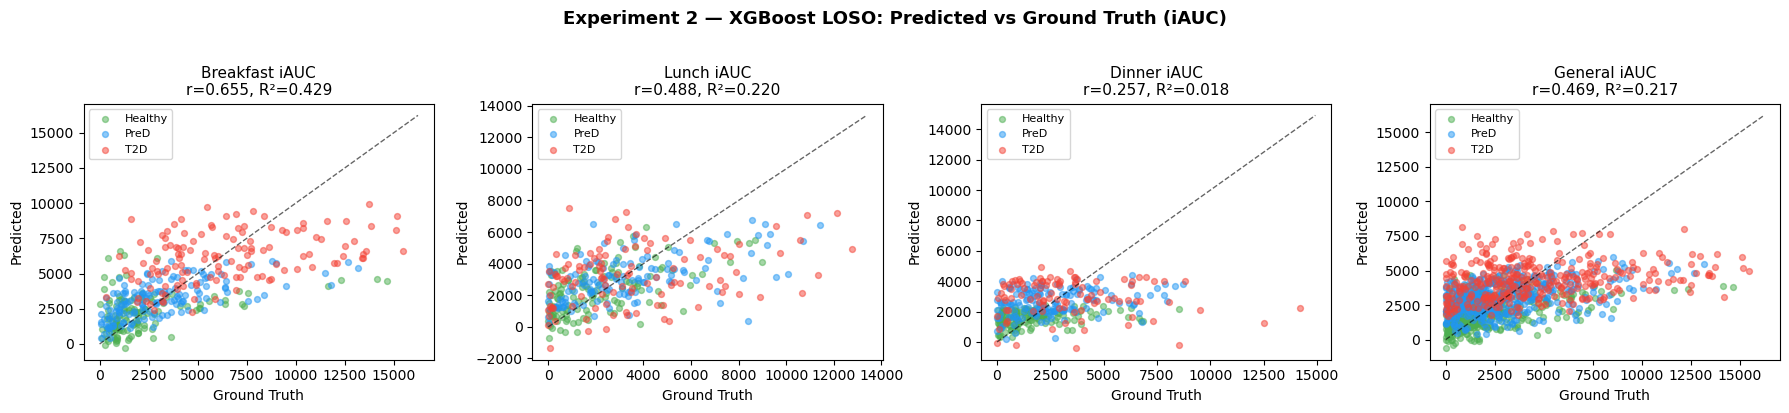

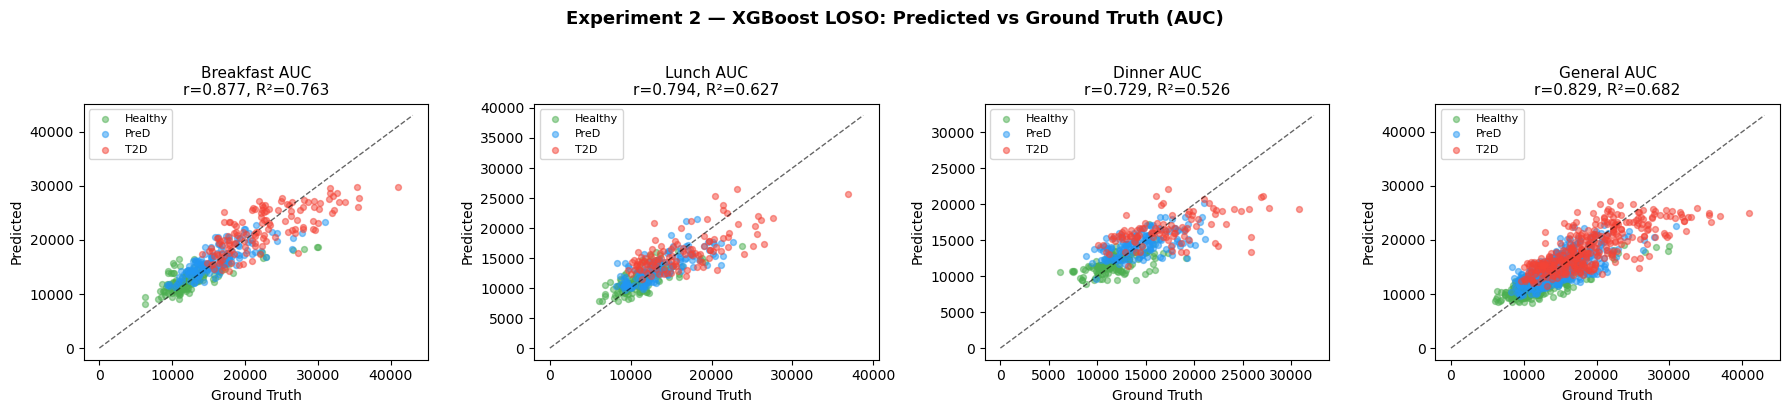

In [10]:
# Summary table
summary = pd.DataFrame({
    'Model':    ['Breakfast', 'Lunch', 'Dinner', 'General'],
    'N_meals':  [405, 369, 396, 1170],
    'iAUC_r':   [met_2a['r'],     met_2b['r'],     met_2c['r'],     met_2d['r']],
    'iAUC_R2':  [met_2a['R2'],    met_2b['R2'],    met_2c['R2'],    met_2d['R2']],
    'iAUC_RMSE':[met_2a['RMSE'],  met_2b['RMSE'],  met_2c['RMSE'],  met_2d['RMSE']],
    'AUC_r':    [met_2a_auc['r'],  met_2b_auc['r'],  met_2c_auc['r'],  met_2d_auc['r']],
    'AUC_R2':   [met_2a_auc['R2'], met_2b_auc['R2'], met_2c_auc['R2'], met_2d_auc['R2']],
    'AUC_RMSE': [met_2a_auc['RMSE'],met_2b_auc['RMSE'],met_2c_auc['RMSE'],met_2d_auc['RMSE']],
})

print(summary.round(3).to_string(index=False))

# Scatter plots: predicted vs ground truth
HEALTH_COLORS = {'Healthy': '#4CAF50', 'PreD': '#2196F3', 'T2D': '#F44336'}

def scatter_pred_vs_true(results_df, title, ax):
    for hg, grp in results_df.groupby('Health_group'):
        ax.scatter(grp['y_true'], grp['y_pred'],
                   c=HEALTH_COLORS[hg], label=hg, alpha=0.5, s=18)
    
    lim = max(results_df['y_true'].max(), results_df['y_pred'].max()) * 1.05
    ax.plot([0, lim], [0, lim], 'k--', linewidth=1, alpha=0.6)
    
    r, _ = scipy.stats.pearsonr(results_df['y_true'], results_df['y_pred'])
    r2   = r2_score(results_df['y_true'], results_df['y_pred'])
    ax.set_title(f'{title}\nr={r:.3f}, R²={r2:.3f}', fontsize=11)
    ax.set_xlabel('Ground Truth')
    ax.set_ylabel('Predicted')
    ax.legend(fontsize=8)

# iAUC — 4 panels
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
scatter_pred_vs_true(res_2a, 'Breakfast iAUC', axes[0])
scatter_pred_vs_true(res_2b, 'Lunch iAUC',     axes[1])
scatter_pred_vs_true(res_2c, 'Dinner iAUC',    axes[2])
scatter_pred_vs_true(res_2d, 'General iAUC',   axes[3])
plt.suptitle('Experiment 2 — XGBoost LOSO: Predicted vs Ground Truth (iAUC)', 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('exp2_iauc_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

# AUC — 4 panels
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
scatter_pred_vs_true(res_2a_auc, 'Breakfast AUC', axes[0])
scatter_pred_vs_true(res_2b_auc, 'Lunch AUC',     axes[1])
scatter_pred_vs_true(res_2c_auc, 'Dinner AUC',    axes[2])
scatter_pred_vs_true(res_2d_auc, 'General AUC',   axes[3])
plt.suptitle('Experiment 2 — XGBoost LOSO: Predicted vs Ground Truth (AUC)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('exp2_auc_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


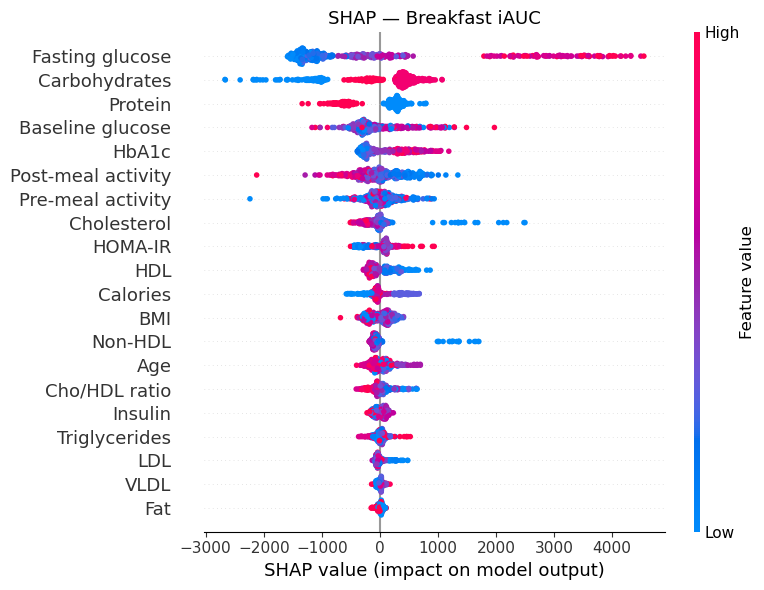

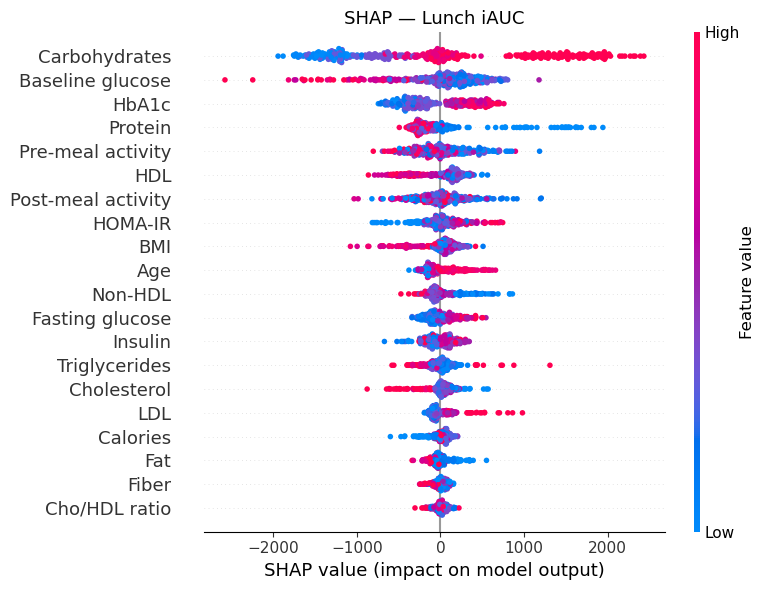

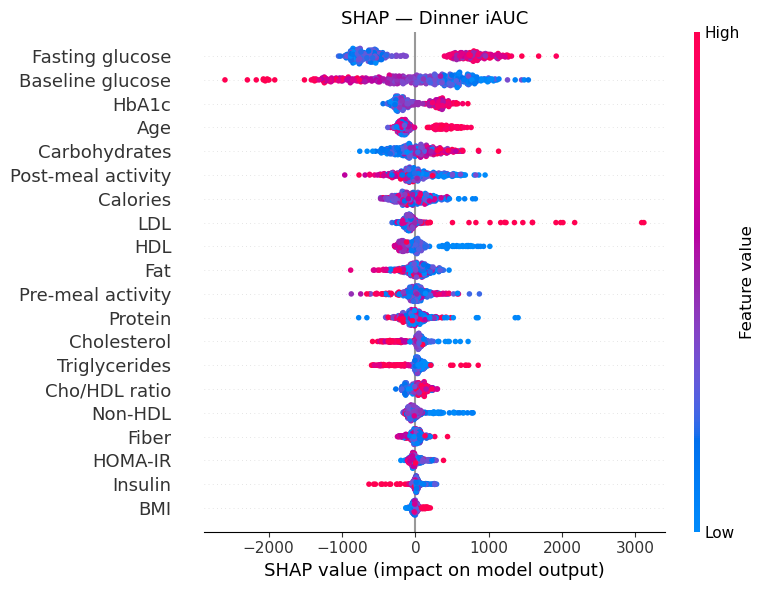

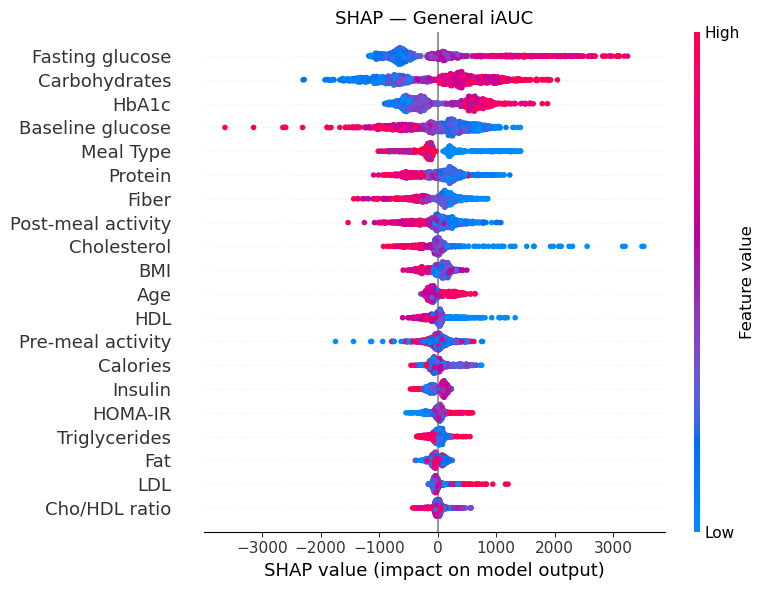

array([[  100.54057 ,  -273.69653 ,    47.369503, ...,   -87.53243 ,
         -173.75723 ,  -120.903786],
       [ -686.53253 ,   287.49664 ,  -149.8876  , ...,   152.35019 ,
          251.3289  ,   -60.55618 ],
       [  368.4739  ,   216.71982 ,    49.098133, ...,    51.278145,
         -299.41312 ,   202.14105 ],
       ...,
       [ -793.9693  ,   -59.03305 ,   250.78015 , ...,   -22.858566,
          692.3497  ,  -614.7266  ],
       [-1827.7999  ,   235.11504 ,   153.34402 , ...,  -167.84534 ,
         -649.97815 ,   742.1234  ],
       [ 1287.997   ,  -297.17416 ,   -79.314026, ...,   153.22589 ,
          463.42496 ,  -616.93353 ]], shape=(1170, 23), dtype=float32)

In [11]:
import shap

# Train final models on full data for SHAP 
def train_final_model(df, features, target='iAUC_libre'):
    X = df[features].values
    y = df[target].values

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Deeper model for interpretable SHAP — NOT the shallow LOSO model
    mdl = xgb.XGBRegressor(
        max_depth=4, n_estimators=200, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        random_state=42
    )
    mdl.fit(X_scaled, y)
    return mdl, scaler, pd.DataFrame(X_scaled, columns=features)

# SHAP summary plot for one model
def plot_shap(mdl, X_df, title, ax=None, show=True):
    explainer   = shap.TreeExplainer(mdl)
    shap_values = explainer.shap_values(X_df)

    if show:
        plt.figure(figsize=(8, 6))
        shap.summary_plot(shap_values, X_df, show=False, plot_size=None)
        plt.title(title, fontsize=13)
        plt.tight_layout()
        plt.savefig(f'shap_{title.replace(" ", "_").replace("/", "")}.png',
                    dpi=150, bbox_inches='tight')
        plt.show()

    return shap_values

# Feature name mapping for cleaner labels 
FEATURE_LABELS = {
    'Carbs_kcal':      'Carbohydrates',
    'Protein_kcal':    'Protein',
    'Fat_kcal':        'Fat',
    'Fiber_kcal':      'Fiber',
    'Baseline_Libre':  'Baseline glucose',
    'Age':             'Age',
    'Gender_encoded':  'Gender',
    'BMI':             'BMI',
    'A1c':             'HbA1c',
    'HOMA_IR':         'HOMA-IR',
    'Insulin':         'Insulin',
    'Triglycerides':   'Triglycerides',
    'Cholesterol':     'Cholesterol',
    'HDL':             'HDL',
    'Non_HDL':         'Non-HDL',
    'LDL':             'LDL',
    'VLDL':            'VLDL',
    'Cho_HDL_ratio':   'Cho/HDL ratio',
    'Fasting_glucose': 'Fasting glucose',
    'Calories':        'Calories',
    'Activity_pre_sum':  'Pre-meal activity',
    'Activity_post_sum': 'Post-meal activity',
    'Meal_Type_encoded': 'Meal Type',
    'Net_Carb':        'Net Carbs',
}

# Train all 4 models
mdl_b,  scaler_b,  X_b  = train_final_model(breakfast_df,   FEATURES,         target='iAUC_libre')
mdl_l,  scaler_l,  X_l  = train_final_model(lunch_df,       FEATURES,         target='iAUC_libre')
mdl_d,  scaler_d,  X_d  = train_final_model(dinner_df,      FEATURES,         target='iAUC_libre')
mdl_g,  scaler_g,  X_g  = train_final_model(df,             FEATURES_GENERAL, target='iAUC_libre')

# Rename columns for readable SHAP plots
X_b = X_b.rename(columns=FEATURE_LABELS)
X_l = X_l.rename(columns=FEATURE_LABELS)
X_d = X_d.rename(columns=FEATURE_LABELS)
X_g = X_g.rename(columns=FEATURE_LABELS)

# Plot SHAP for each model
plot_shap(mdl_b, X_b, title='SHAP — Breakfast iAUC')
plot_shap(mdl_l, X_l, title='SHAP — Lunch iAUC')
plot_shap(mdl_d, X_d, title='SHAP — Dinner iAUC')
plot_shap(mdl_g, X_g, title='SHAP — General iAUC')

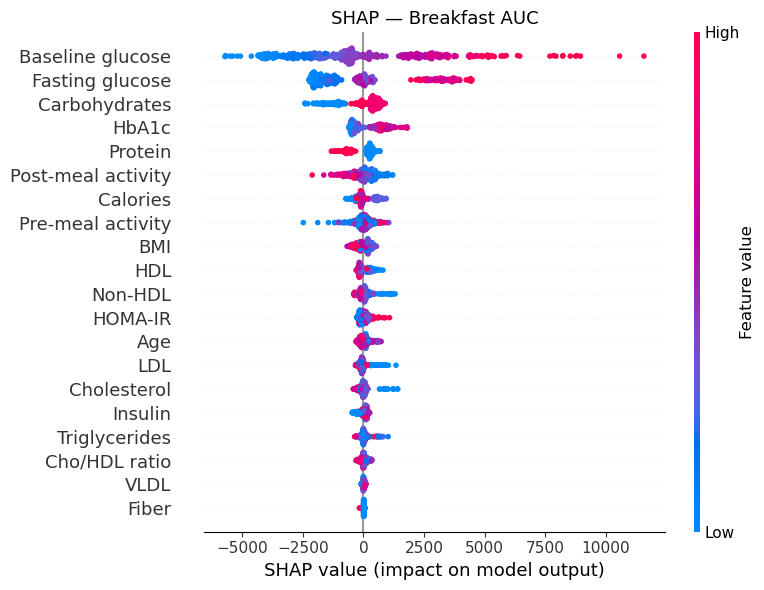

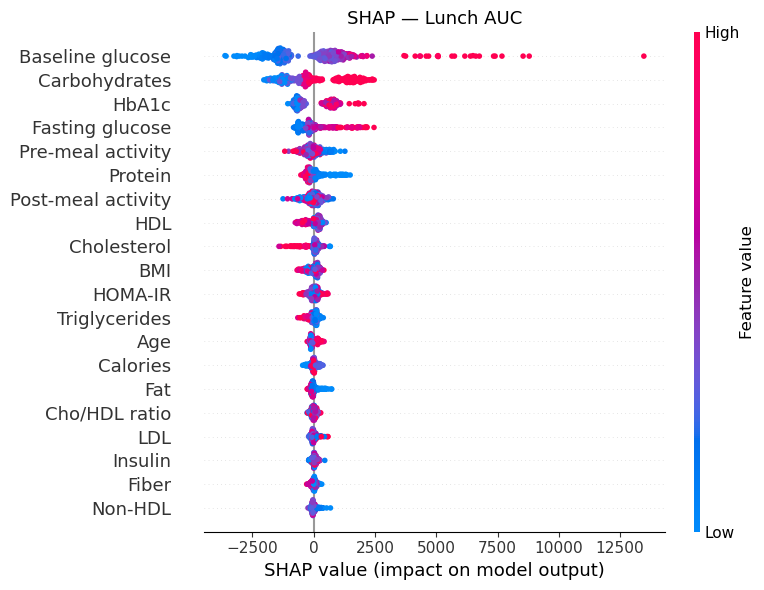

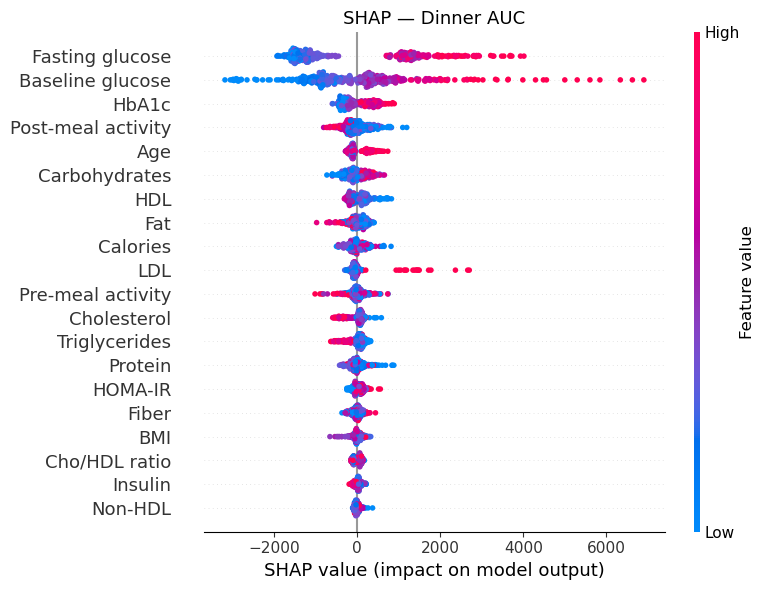

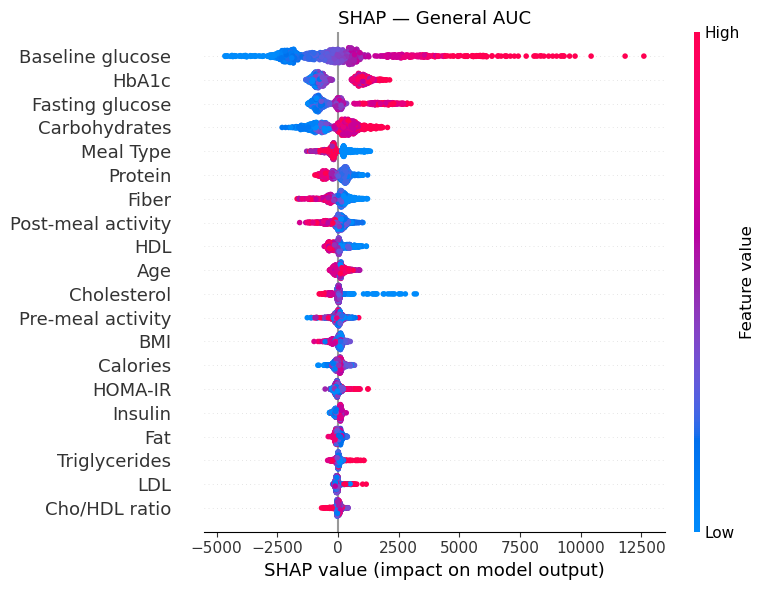

array([[   64.07034 ,  -471.11642 ,    27.228113, ...,  -134.93744 ,
          -77.37756 ,  -180.49026 ],
       [ -656.07715 ,   247.20078 ,   -64.430626, ...,    81.19245 ,
          137.29001 ,  -133.109   ],
       [  376.60144 ,   327.4596  ,    94.25818 , ...,    33.240547,
         -378.70798 ,   205.54987 ],
       ...,
       [ -911.39954 ,    32.165043,   154.14832 , ...,    31.88591 ,
          203.38652 ,  -499.2544  ],
       [-1684.9973  ,   246.89192 ,    96.44482 , ...,  -274.83392 ,
         -568.51373 ,   964.29645 ],
       [ 1460.8319  ,  -142.86342 ,   -96.693214, ...,   234.83104 ,
          243.04445 ,  -579.1294  ]], shape=(1170, 23), dtype=float32)

In [ ]:
# Train final models for AUC
mdl_b_auc, _, X_b_auc = train_final_model(breakfast_df,   FEATURES,         target='AUC_libre')
mdl_l_auc, _, X_l_auc = train_final_model(lunch_df,       FEATURES,         target='AUC_libre')
mdl_d_auc, _, X_d_auc = train_final_model(dinner_df,      FEATURES,         target='AUC_libre')
mdl_g_auc, _, X_g_auc = train_final_model(df,             FEATURES_GENERAL, target='AUC_libre')

# Rename for readable labels
X_b_auc = X_b_auc.rename(columns=FEATURE_LABELS)
X_l_auc = X_l_auc.rename(columns=FEATURE_LABELS)
X_d_auc = X_d_auc.rename(columns=FEATURE_LABELS)
X_g_auc = X_g_auc.rename(columns=FEATURE_LABELS)

# Plot
plot_shap(mdl_b_auc, X_b_auc, title='SHAP — Breakfast AUC')
plot_shap(mdl_l_auc, X_l_auc, title='SHAP — Lunch AUC')
plot_shap(mdl_d_auc, X_d_auc, title='SHAP — Dinner AUC')
plot_shap(mdl_g_auc, X_g_auc, title='SHAP — General AUC')

In [13]:
import pickle

# Save all XGBoost results
xgb_results = {
    'met_2a': met_2a, 'met_2b': met_2b, 'met_2c': met_2c, 'met_2d': met_2d,
    'res_2a': res_2a, 'res_2b': res_2b, 'res_2c': res_2c, 'res_2d': res_2d,
}
with open('xgb_results.pkl', 'wb') as f:
    pickle.dump(xgb_results, f)

print("Saved xgb_results.pkl")

Saved xgb_results.pkl


### Fairness analysis by health group
What is going wrong and maybe some indications for how to improve the performance of the models

FAIRNESS ANALYSIS — XGBoost performance by health group
    Model Health_group  N_meals      r     R2   RMSE    MAE
Breakfast      Healthy      130  0.386  0.126 2391.3 1567.8
Breakfast         PreD      146  0.640  0.388 2032.1 1492.4
Breakfast          T2D      129  0.419  0.163 3276.4 2624.5
    Lunch      Healthy      130  0.580  0.308 1703.2 1341.5
    Lunch         PreD      130  0.532  0.277 2257.3 1711.3
    Lunch          T2D      109  0.318  0.011 3040.4 2480.1
   Dinner      Healthy      142  0.279  0.073 1578.6 1123.0
   Dinner         PreD      155  0.281  0.059 1940.7 1514.9
   Dinner          T2D       99 -0.081 -0.285 3061.6 2283.4
  General      Healthy      402  0.398  0.147 1954.1 1372.3
  General         PreD      431  0.432  0.186 2197.1 1704.9
  General          T2D      337  0.232  0.025 3442.1 2701.2


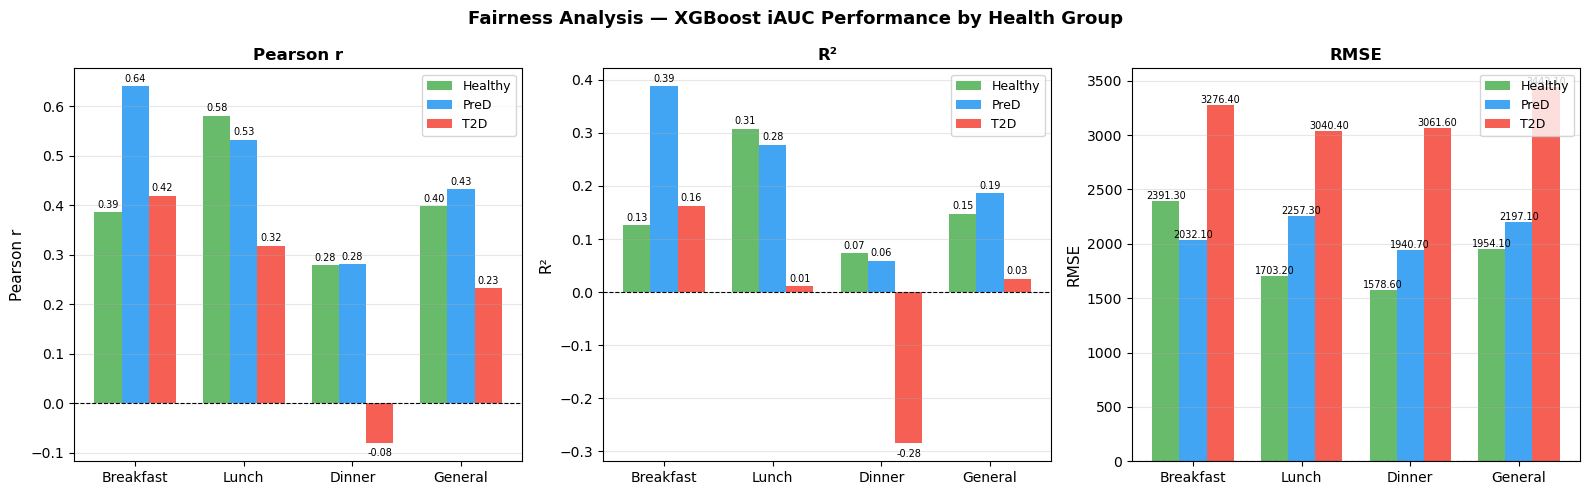

In [14]:
def fairness_by_group(results_dict, model_labels):
    """
    Compute r, R², RMSE per health group for each model.
    results_dict: {'label': results_df, ...}
    """
    rows = []
    for label, res_df in results_dict.items():
        for hg in ['Healthy', 'PreD', 'T2D']:
            subset = res_df[res_df['Health_group'] == hg]
            if len(subset) < 5:
                continue
            r, _  = scipy.stats.pearsonr(subset['y_true'], subset['y_pred'])
            r2    = r2_score(subset['y_true'], subset['y_pred'])
            rmse  = np.sqrt(mean_squared_error(subset['y_true'], subset['y_pred']))
            mae   = mean_absolute_error(subset['y_true'], subset['y_pred'])
            rows.append({
                'Model':        label,
                'Health_group': hg,
                'N_meals':      len(subset),
                'r':            round(r,    3),
                'R2':           round(r2,   3),
                'RMSE':         round(rmse, 1),
                'MAE':          round(mae,  1),
            })
    return pd.DataFrame(rows)

# Run on all XGBoost models
fairness_df = fairness_by_group({
    'Breakfast': res_2a,
    'Lunch':     res_2b,
    'Dinner':    res_2c,
    'General':   res_2d,
}, model_labels=['Breakfast', 'Lunch', 'Dinner', 'General'])

print("="*65)
print("FAIRNESS ANALYSIS — XGBoost performance by health group")
print("="*65)
print(fairness_df.to_string(index=False))

# Plot
HEALTH_COLORS = {'Healthy': '#4CAF50', 'PreD': '#2196F3', 'T2D': '#F44336'}
models        = ['Breakfast', 'Lunch', 'Dinner', 'General']
metrics       = ['r', 'R2', 'RMSE']
titles        = ['Pearson r', 'R²', 'RMSE']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric, title in zip(axes, metrics, titles):
    x     = np.arange(len(models))
    width = 0.25

    for i, hg in enumerate(['Healthy', 'PreD', 'T2D']):
        vals = []
        for model in models:
            row = fairness_df[
                (fairness_df['Model'] == model) &
                (fairness_df['Health_group'] == hg)
            ]
            vals.append(row[metric].values[0] if len(row) > 0 else 0)

        offset = (i - 1) * width
        bars = ax.bar(x + offset, vals, width,
                      label=hg, color=HEALTH_COLORS[hg], alpha=0.85)

        # Value labels
        for bar, val in zip(bars, vals):
            ypos = bar.get_height()
            offset_text = 0.005 if ypos >= 0 else -0.03
            ax.text(bar.get_x() + bar.get_width()/2,
                    ypos + offset_text,
                    f'{val:.2f}', ha='center', va='bottom', fontsize=7)

    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel(title, fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Fairness Analysis — XGBoost iAUC Performance by Health Group',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fairness_by_health_group.png', dpi=150, bbox_inches='tight')
plt.show()